# Lab 2: Linear Classification
**Machine Learning (MSc), AAU AAiT SiTE** · Lecture chapter 2A · Lab instructor: Abel T. · Course instructor: Dr Fantahun B.

| Part | Topic | Approx. time |
|---|---|---|
| A | The perceptron learning rule | 30 min |
| B | Logistic regression by gradient descent, with a gradient check | 45 min |
| C | Multiclass: one-versus-rest and softmax regression | 40 min |
| D | Evaluation: confusion matrix, precision, recall, F1, ROC, PR, thresholds | 40 min |
| E | Class imbalance and class weights | 25 min |

**How to work.** Complete every cell marked `# TODO` (replace `None` or `raise NotImplementedError`). Each part ends with a **check cell**; when it prints ✅ you may move on. Answer each **Question** in the markdown cell below it.

**Submission.** The completed `.ipynb` and a PDF export, within one week. The notebook must run from top to bottom without errors.

In [11]:
# Setup: run this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_blobs, make_classification, load_breast_cancer, load_wine, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

def plot_regions(predict_fn, X, y, ax, title, resolution=300):
    # Shade the plane by predicted class and overlay the points
    x0 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, resolution)
    x1 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, resolution)
    g0, g1 = np.meshgrid(x0, x1)
    classes = np.unique(y)
    Z = np.searchsorted(classes, predict_fn(np.c_[g0.ravel(), g1.ravel()])).reshape(g0.shape)
    cmap = ListedColormap(["#9fd3cc", "#f3d29b", "#d9b8e6"][: len(classes)])
    ax.contourf(g0, g1, Z, levels=np.arange(len(classes) + 1) - 0.5, cmap=cmap, alpha=0.6)
    for c, col in zip(classes, ["#0f766e", "#c2410c", "#6b3fa0"]):
        ax.scatter(X[y == c, 0], X[y == c, 1], s=18, color=col, label=f"class {c}", edgecolor="white", linewidth=0.4)
    ax.set_title(title); ax.legend(fontsize=8)

print("Setup complete")

Setup complete


---
## Part A: The perceptron
The perceptron predicts $\hat{y} = \operatorname{sign}(\mathbf{w}^\top\mathbf{x})$ with labels $y \in \{-1, +1\}$ and a bias column of ones in $\mathbf{X}$. It visits the training points one by one and, **only when a point is misclassified** ($y_i\,\mathbf{w}^\top\mathbf{x}_i \le 0$), updates

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\, y_i\, \mathbf{x}_i .$$

The **perceptron convergence theorem** says that if the data are linearly separable this stops after a finite number of mistakes. If they are not, it never settles.

We use two synthetic datasets: one separable and one where the classes overlap.

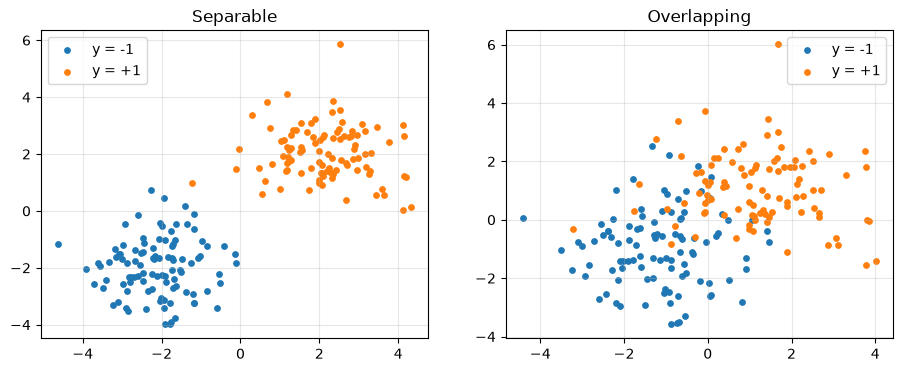

In [12]:
X_sep, y_sep01 = make_blobs(n_samples=200, centers=[[-2, -2], [2, 2]], cluster_std=1.0, random_state=SEED)
X_ovl, y_ovl01 = make_blobs(n_samples=200, centers=[[-1, -1], [1, 1]], cluster_std=1.3, random_state=SEED)
y_sep = np.where(y_sep01 == 1, 1, -1)   # perceptron labels: -1 / +1
y_ovl = np.where(y_ovl01 == 1, 1, -1)

def add_bias(X):
    return np.c_[np.ones(len(X)), X]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, X_, y_, t in [(axes[0], X_sep, y_sep, "Separable"), (axes[1], X_ovl, y_ovl, "Overlapping")]:
    ax.scatter(X_[y_ == -1, 0], X_[y_ == -1, 1], s=15, label="y = -1")
    ax.scatter(X_[y_ == 1, 0], X_[y_ == 1, 1], s=15, label="y = +1")
    ax.set_title(t); ax.legend()
plt.show()

**A1.** Implement `perceptron_fit`. Shuffle the points at the start of each epoch with the given `rng`, apply the update rule to every misclassified point, and record the number of mistakes in each epoch. Stop early when an epoch has no mistakes.

Separable  : stopped after 3 epochs, final mistakes = 0
Overlapping: ran 100 epochs, final mistakes = 33
Training accuracy (overlapping): 0.88


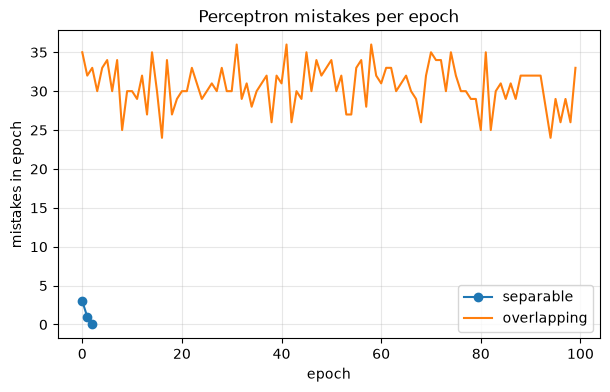

In [13]:
def perceptron_fit(X, y, lr=1.0, max_epochs=100, seed=SEED):
    # X includes the bias column; y in {-1, +1}. Returns (w, mistakes_per_epoch)
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    mistakes = []
    for epoch in range(max_epochs):
        n_mistakes = 0
        for i in rng.permutation(len(X)):
            # TODO: if point i is misclassified, update w and count the mistake
            y_i = X[i] @ w
            if y_i * y[i] <= 0:
                n_mistakes += 1
                w = w + lr * y[i] * X[i]
        mistakes.append(n_mistakes)
        if n_mistakes == 0:
            break
    return w, np.array(mistakes)

def perceptron_predict(X, w):
    return np.where(X @ w >= 0, 1, -1)

w_sep, m_sep = perceptron_fit(add_bias(X_sep), y_sep)
w_ovl, m_ovl = perceptron_fit(add_bias(X_ovl), y_ovl)
print(f"Separable  : stopped after {len(m_sep)} epochs, final mistakes = {m_sep[-1]}")
print(f"Overlapping: ran {len(m_ovl)} epochs, final mistakes = {m_ovl[-1]}")
print("Training accuracy (overlapping):", np.mean(perceptron_predict(add_bias(X_ovl), w_ovl) == y_ovl).round(3))

plt.plot(m_sep, "o-", label="separable")
plt.plot(m_ovl, label="overlapping")
plt.xlabel("epoch"); plt.ylabel("mistakes in epoch"); plt.title("Perceptron mistakes per epoch"); plt.legend(); plt.show()

**A2.** Draw the learned decision boundaries and compare with scikit-learn's `Perceptron`.

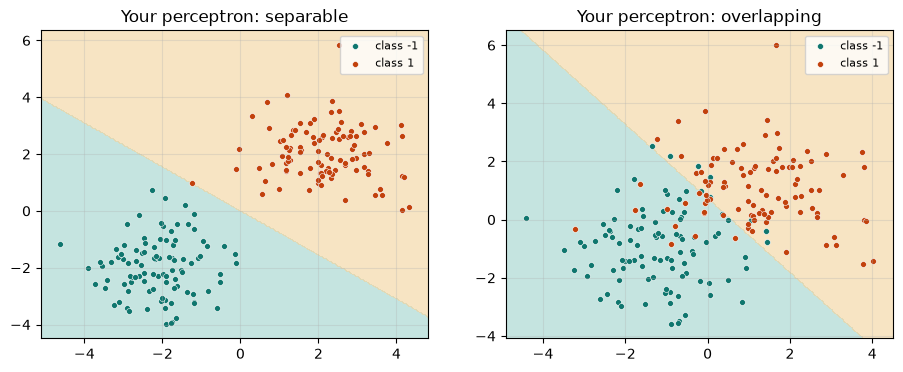

scikit-learn Perceptron, separable training accuracy: None


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_regions(lambda Z: perceptron_predict(add_bias(Z), w_sep), X_sep, y_sep, axes[0], "Your perceptron: separable")
plot_regions(lambda Z: perceptron_predict(add_bias(Z), w_ovl), X_ovl, y_ovl, axes[1], "Your perceptron: overlapping")
plt.show()

# TODO: fit sklearn's Perceptron(random_state=SEED) on the separable data and report its training accuracy as sk_acc_sep
sk_perc = None
sk_acc_sep = None
print("scikit-learn Perceptron, separable training accuracy:", sk_acc_sep)

In [15]:
# Check Part A
assert m_sep[-1] == 0 and len(m_sep) < 100, "the perceptron should converge on separable data"
assert np.all(perceptron_predict(add_bias(X_sep), w_sep) == y_sep)
assert len(m_ovl) == 100 and m_ovl.min() > 0, "on overlapping data the perceptron should never reach zero mistakes"
assert sk_acc_sep == 1.0
print("✅ Part A checks passed")

AssertionError: 

> **Question A.** (a) Why does the perceptron stop on the separable data but not on the overlapping data? (b) On the overlapping data, does the final weight vector give the best boundary the perceptron saw? Suggest a simple fix. (c) The perceptron gives a class but no probability. Why is that a limitation?

**Your answer:**

*Write your answer here.*

---
## Part B: Logistic regression from scratch
Logistic regression models the probability of the positive class with the sigmoid,
$$p(y=1\mid\mathbf{x}) = \sigma(\mathbf{w}^\top\mathbf{x}), \qquad \sigma(z) = \frac{1}{1+e^{-z}},$$
and is trained by minimising the mean **binary cross-entropy** with labels $y \in \{0, 1\}$:
$$J(\mathbf{w}) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big], \qquad \nabla J = \frac{1}{n}\mathbf{X}^\top(\mathbf{p}-\mathbf{y}).$$

**Data.** Breast Cancer Wisconsin, 569 tumours and 30 features. scikit-learn codes *benign* as 1; we flip it so that **malignant = 1 is the positive class**. We use a stratified 75/25 split and standardise with a scaler fitted on the training set.

In [ ]:
bc = load_breast_cancer()
X_bc = bc.data
y_bc = 1 - bc.target                     # 1 = malignant (positive), 0 = benign
print("Class counts (0 = benign, 1 = malignant):", np.bincount(y_bc))

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=SEED)
scaler_bc = StandardScaler().fit(Xb_tr)
Xb_tr_s = add_bias(scaler_bc.transform(Xb_tr))
Xb_te_s = add_bias(scaler_bc.transform(Xb_te))
print("train:", Xb_tr_s.shape, " test:", Xb_te_s.shape)

**B1.** Implement the sigmoid, the cross-entropy loss and its gradient. Clip probabilities to $[10^{-12}, 1-10^{-12}]$ inside the loss so that $\log 0$ never happens.

In [ ]:
def sigmoid(z):
    # TODO
    raise NotImplementedError

def bce_loss(w, X, y):
    # TODO: mean binary cross-entropy
    raise NotImplementedError

def bce_grad(w, X, y):
    # TODO: gradient of the mean cross-entropy
    raise NotImplementedError

**B2. Gradient check.** Before trusting a gradient, compare it with central finite differences:
$$\frac{\partial J}{\partial w_j} \approx \frac{J(\mathbf{w}+\varepsilon\mathbf{e}_j) - J(\mathbf{w}-\varepsilon\mathbf{e}_j)}{2\varepsilon}.$$
Implement `numerical_grad` and report the relative error $\lVert g_{\text{num}} - g\rVert / (\lVert g_{\text{num}}\rVert + \lVert g\rVert)$. Below about $10^{-7}$ means the gradient is right.

In [ ]:
def numerical_grad(f, w, eps=1e-5):
    g = np.zeros_like(w)
    for j in range(len(w)):
        # TODO: central difference along coordinate j
        raise NotImplementedError
    return g

w_test = np.random.default_rng(0).normal(scale=0.1, size=Xb_tr_s.shape[1])
g_ana = bce_grad(w_test, Xb_tr_s, yb_tr)
g_num = numerical_grad(lambda w: bce_loss(w, Xb_tr_s, yb_tr), w_test)
rel_err = np.linalg.norm(g_num - g_ana) / (np.linalg.norm(g_num) + np.linalg.norm(g_ana))
print(f"Relative error between numerical and analytical gradient: {rel_err:.2e}")

**B3.** Train with gradient descent ($\eta = 0.5$, 3,000 iterations), plot the loss, and compare test accuracy with scikit-learn's `LogisticRegression`.

In [ ]:
def logistic_fit(X, y, lr=0.5, n_iters=3000):
    w = np.zeros(X.shape[1]); history = []
    for _ in range(n_iters):
        # TODO: one gradient step, then record the loss
        raise NotImplementedError
    return w, np.array(history)

def logistic_predict_proba(X, w):
    return sigmoid(X @ w)

w_lr, hist_lr = logistic_fit(Xb_tr_s, yb_tr)
p_te = logistic_predict_proba(Xb_te_s, w_lr)
acc_mine = accuracy_score(yb_te, (p_te >= 0.5).astype(int))

sk_lr = LogisticRegression(max_iter=5000).fit(Xb_tr_s[:, 1:], yb_tr)
acc_sk = sk_lr.score(Xb_te_s[:, 1:], yb_te)
print(f"Test accuracy, yours: {acc_mine:.3f}   scikit-learn: {acc_sk:.3f}")
print(f"Final training loss: {hist_lr[-1]:.4f}   largest |weight|: {np.abs(w_lr).max():.1f}")

plt.plot(np.arange(1, len(hist_lr) + 1), hist_lr)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("iteration (log scale)"); plt.ylabel("cross-entropy (log scale)")
plt.title("Logistic regression training loss"); plt.show()

**B4. Training longer.** Train for 300, 3,000 and 30,000 iterations and watch the size of the weights, the training loss and the test accuracy.

In [ ]:
rows = []
for n_it in [300, 3000, 30000]:
    w_n, h_n = logistic_fit(Xb_tr_s, yb_tr, lr=0.5, n_iters=n_it)
    rows.append(dict(iterations=n_it, weight_norm=np.linalg.norm(w_n), train_loss=h_n[-1],
                     test_accuracy=accuracy_score(yb_te, (logistic_predict_proba(Xb_te_s, w_n) >= 0.5).astype(int))))
longer = pd.DataFrame(rows).set_index("iterations")
display(longer.round(4))

In [ ]:
# Check Part B
assert np.isclose(sigmoid(0.0), 0.5) and sigmoid(50) > 0.999 and sigmoid(-50) < 1e-3
assert np.isclose(bce_loss(np.zeros(Xb_tr_s.shape[1]), Xb_tr_s, yb_tr), np.log(2)), "with w = 0 the loss is log 2"
assert rel_err < 1e-7, "your analytical gradient does not match the numerical one"
assert np.all(np.diff(hist_lr) <= 1e-12), "loss should decrease at every step"
assert acc_mine >= 0.95, "test accuracy should be at least 0.95"
assert longer["weight_norm"].is_monotonic_increasing and longer["train_loss"].is_monotonic_decreasing
print("✅ Part B checks passed")

> **Question B.** (a) Why is the loss exactly log 2 when **w** = 0? (b) Why do we check gradients numerically, and why use a central rather than a one-sided difference? (c) In B4 the training loss keeps falling and the weights keep growing while test accuracy drops. What does this tell you about the training data, and what does scikit-learn do differently (look at its default `C`)?

**Your answer:**

*Write your answer here.*

---
## Part C: More than two classes
**One-versus-rest (OvR).** Train one binary logistic regression per class ("class k" against "everything else") and predict the class whose model gives the highest probability.

**Softmax regression.** One weight vector per class, collected as the columns of $\mathbf{W}$, and probabilities that sum to one:
$$P(y = k\mid\mathbf{x}) = \frac{e^{\mathbf{w}_k^\top\mathbf{x}}}{\sum_{j} e^{\mathbf{w}_j^\top\mathbf{x}}}, \qquad J = -\frac{1}{n}\sum_i \log P(y_i\mid\mathbf{x}_i), \qquad \nabla_{\mathbf{W}} J = \frac{1}{n}\mathbf{X}^\top(\mathbf{P}-\mathbf{Y}),$$
where $\mathbf{Y}$ is the one-hot label matrix.

**Data.** Wine: 178 wines, 13 chemical features, 3 cultivars. Stratified 70/30 split, standardised.

In [ ]:
wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.3, stratify=wine.target, random_state=SEED)
scaler_w = StandardScaler().fit(Xw_tr)
Xw_tr_s, Xw_te_s = add_bias(scaler_w.transform(Xw_tr)), add_bias(scaler_w.transform(Xw_te))
K = 3
print("train:", Xw_tr_s.shape, " test:", Xw_te_s.shape, " class counts:", np.bincount(yw_tr))

**C1.** Implement one-versus-rest using your `logistic_fit` from Part B (use `lr=0.5, n_iters=2000`).

In [ ]:
def ovr_fit(X, y, n_classes):
    # Returns a (d, n_classes) matrix whose column k is the binary model for class k
    # TODO
    raise NotImplementedError

def ovr_predict(X, W):
    return np.argmax(sigmoid(X @ W), axis=1)

W_ovr = ovr_fit(Xw_tr_s, yw_tr, K)
acc_ovr = accuracy_score(yw_te, ovr_predict(Xw_te_s, W_ovr))
print(f"OvR test accuracy: {acc_ovr:.3f}")

**C2.** Implement softmax regression. Subtract the row maximum before exponentiating so that `np.exp` never overflows.

In [ ]:
def softmax(Z):
    # TODO: numerically stable softmax along axis 1
    raise NotImplementedError

def one_hot(y, n_classes):
    return np.eye(n_classes)[y]

def softmax_fit(X, y, n_classes, lr=0.5, n_iters=2000):
    W = np.zeros((X.shape[1], n_classes)); Y = one_hot(y, n_classes); history = []
    for _ in range(n_iters):
        # TODO: compute P, update W with the gradient, record the cross-entropy
        raise NotImplementedError
    return W, np.array(history)

W_sm, hist_sm = softmax_fit(Xw_tr_s, yw_tr, K)
P_te = softmax(Xw_te_s @ W_sm)
acc_sm = accuracy_score(yw_te, P_te.argmax(axis=1))
acc_sk_multi = LogisticRegression(max_iter=5000).fit(Xw_tr_s[:, 1:], yw_tr).score(Xw_te_s[:, 1:], yw_te)
print(f"Softmax test accuracy: {acc_sm:.3f}   scikit-learn LogisticRegression: {acc_sk_multi:.3f}")
print("First three test rows, predicted probabilities:\n", P_te[:3].round(3))

**C3.** Visualise the two approaches on a 2D problem: Iris with only petal length and petal width.

In [ ]:
iris = load_iris()
Xi = iris.data[:, 2:4]; yi = iris.target
sc_i = StandardScaler().fit(Xi)
Xi_s = sc_i.transform(Xi)
W_ovr_i = ovr_fit(add_bias(Xi_s), yi, 3)
W_sm_i, _ = softmax_fit(add_bias(Xi_s), yi, 3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_regions(lambda Z: ovr_predict(add_bias(Z), W_ovr_i), Xi_s, yi, axes[0], "One-versus-rest")
plot_regions(lambda Z: softmax(add_bias(Z) @ W_sm_i).argmax(axis=1), Xi_s, yi, axes[1], "Softmax regression")
for ax in axes: ax.set_xlabel("petal length (scaled)"); ax.set_ylabel("petal width (scaled)")
plt.tight_layout(); plt.show()

# How confident is OvR? Its three probabilities need not sum to one
s = sigmoid(add_bias(Xi_s) @ W_ovr_i).sum(axis=1)
print(f"OvR probability sums: min {s.min():.2f}, max {s.max():.2f}")

In [ ]:
# Check Part C
assert W_ovr.shape == (14, 3) and W_sm.shape == (14, 3)
assert np.allclose(softmax(np.array([[1000., 1000.], [0., np.log(3)]])), [[0.5, 0.5], [0.25, 0.75]]), "softmax is not stable or not correct"
assert np.allclose(P_te.sum(axis=1), 1)
assert acc_ovr >= 0.94 and acc_sm >= 0.94, "both multiclass models should reach at least 0.94 test accuracy"
assert np.all(np.diff(hist_sm) <= 1e-12)
print("✅ Part C checks passed")

> **Question C.** (a) How many weight vectors do OvR and softmax use for K classes, and how do they differ in what they optimise? (b) The OvR probabilities do not sum to one. Why not, and why does that matter if you want calibrated probabilities? (c) Why does subtracting the row maximum not change the softmax output? (d) Look at the decision regions: where do the two methods disagree?

**Your answer:**

*Write your answer here.*

---
## Part D: Evaluating a classifier
We return to Breast Cancer and your logistic regression's test probabilities `p_te`. With malignant as the positive class:

| | predicted malignant | predicted benign |
|---|---|---|
| **actually malignant** | TP | FN (a missed cancer) |
| **actually benign** | FP (a false alarm) | TN |

$$\text{precision} = \frac{TP}{TP+FP}, \quad \text{recall} = \frac{TP}{TP+FN}, \quad F_1 = \frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}.$$

**D1.** Compute the confusion-matrix counts and the three metrics yourself at threshold 0.5, and check them against scikit-learn.

In [ ]:
def binary_metrics(y_true, y_pred):
    # Returns dict with tp, fp, fn, tn, precision, recall, f1
    # TODO
    raise NotImplementedError

yhat_te = (p_te >= 0.5).astype(int)
m = binary_metrics(yb_te, yhat_te)
print(m)
print("scikit-learn:", dict(precision=precision_score(yb_te, yhat_te), recall=recall_score(yb_te, yhat_te), f1=f1_score(yb_te, yhat_te)))
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay(confusion_matrix(yb_te, yhat_te), display_labels=["benign", "malignant"]).plot(cmap="Blues", colorbar=False, ax=ax)
plt.grid(False); plt.title("Test confusion matrix, threshold 0.5"); plt.show()

**D2. The threshold.** Sweep the threshold from 0.05 to 0.95 and plot precision, recall and F1. Then find `t_recall`, the **largest** threshold whose recall on the test set is at least 0.95.

*(In practice you would choose the threshold on a validation set, not on the test set. We use the test set here only to keep the lab short.)*

In [ ]:
thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)
# TODO: build sweep, a DataFrame indexed by threshold with columns precision, recall, f1
sweep = None

sweep.plot(marker="o", ms=3)
plt.xlabel("decision threshold"); plt.ylabel("score"); plt.ylim(0.7, 1.01); plt.title("Precision, recall and F1 against threshold"); plt.show()

# TODO: t_recall = the largest threshold in `thresholds` with recall >= 0.95
t_recall = None
print("Largest threshold with recall >= 0.95:", t_recall)
print(sweep.loc[[0.5, t_recall]].round(3))

**D3. ROC and precision-recall curves.** These summarise performance across *all* thresholds.

In [ ]:
# TODO: compute fpr, tpr (roc_curve), auc_roc (roc_auc_score), prec, rec (precision_recall_curve), ap (average_precision_score)
fpr, tpr, auc_roc = None, None, None
prec, rec, ap = None, None, None

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(fpr, tpr, label=f"logistic regression (AUC = {auc_roc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="random (AUC = 0.5)")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)"); axes[0].set_title("ROC curve"); axes[0].legend()
axes[1].plot(rec, prec, label=f"logistic regression (AP = {ap:.3f})")
axes[1].axhline(yb_te.mean(), color="k", ls="--", label=f"random (AP = {yb_te.mean():.2f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Check Part D
assert m["tp"] + m["fp"] + m["fn"] + m["tn"] == len(yb_te)
assert np.isclose(m["precision"], precision_score(yb_te, yhat_te)) and np.isclose(m["recall"], recall_score(yb_te, yhat_te))
assert np.isclose(m["f1"], f1_score(yb_te, yhat_te))
assert list(sweep.columns) == ["precision", "recall", "f1"] and len(sweep) == len(thresholds)
assert sweep.loc[t_recall, "recall"] >= 0.95 and t_recall < 0.5, "a high-recall threshold should be below 0.5 here"
assert auc_roc > 0.98 and ap > 0.97
print("✅ Part D checks passed")

> **Question D.** (a) For cancer screening, which error is worse, a false negative or a false positive? Which metric should you watch most closely? (b) Compare threshold 0.5 with `t_recall`: how many more malignant tumours are caught, and what does it cost in precision? (c) What does an ROC AUC of about 0.99 mean in words? (d) When would you prefer the precision-recall curve to the ROC curve?

**Your answer:**

*Write your answer here.*

---
## Part E: Class imbalance
Many real problems (fraud, rare diseases, defects) have very few positives. We generate 5,000 samples in which only **5% are positive**.

In [ ]:
X_im, y_im = make_classification(n_samples=5000, n_features=10, n_informative=4, n_redundant=2,
                                 weights=[0.95], flip_y=0.01, class_sep=2.0, random_state=SEED)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_im, y_im, test_size=0.3, stratify=y_im, random_state=SEED)
print("Positive rate, train:", yi_tr.mean().round(3), " test:", yi_te.mean().round(3))

**E1.** Compare three models on the test set: a **majority-class baseline** (`DummyClassifier(strategy="most_frequent")`), plain **logistic regression**, and logistic regression with **`class_weight="balanced"`**, which weights each class by $n / (2\,n_c)$ so both classes contribute equally to the loss. Put scaling and the model in a `Pipeline`. Report accuracy, precision, recall, F1 and average precision (AP) in a DataFrame `imb_results`, one row per model.

In [ ]:
imb_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))]),
    "Logistic, balanced": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
}

# TODO: fit each model on (Xi_tr, yi_tr) and fill imb_results
#       (for AP use predict_proba(...)[:, 1]; use zero_division=0 in precision_score)
imb_results = None
display(imb_results.round(3))

imb_results[["accuracy", "recall", "f1"]].plot.bar(rot=0, figsize=(8, 4))
plt.title("Accuracy hides the problem; recall and F1 reveal it"); plt.ylim(0, 1.05)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**E2.** Compare the ROC AUC and AP of the plain logistic model. Which number gives the more honest picture here?

In [ ]:
p_im = imb_models["Logistic"].predict_proba(Xi_te)[:, 1]
auc_im = roc_auc_score(yi_te, p_im)
print(f"ROC AUC = {auc_im:.3f}    AP = {imb_results.loc['Logistic', 'AP']:.3f}    (AP of a random classifier = {yi_te.mean():.3f})")

In [ ]:
# Check Part E
assert list(imb_results.columns) == ["accuracy", "precision", "recall", "f1", "AP"]
assert imb_results.loc["Majority baseline", "accuracy"] > 0.93 and imb_results.loc["Majority baseline", "recall"] == 0
assert imb_results.loc["Logistic, balanced", "recall"] > imb_results.loc["Logistic", "recall"] + 0.2, "class weights should raise recall a lot"
assert imb_results.loc["Logistic, balanced", "precision"] < imb_results.loc["Logistic", "precision"]
assert auc_im > imb_results.loc["Logistic", "AP"]
print("✅ Part E checks passed")

> **Question E.** (a) The majority baseline is about 95% accurate, and plain logistic regression barely beats it. Why is it useless? (b) What did class weighting do to recall and to precision, and why? (c) Class weights and lowering the threshold (Part D) both raise recall. How are they similar and how do they differ? (d) Why is the ROC AUC so much higher than the AP here, and which would you report?

**Your answer:**

*Write your answer here.*

---
## Summary
* The **perceptron** converges only on separable data and gives no probabilities.
* **Logistic regression** minimises cross-entropy; **check your gradients** numerically. On separable data its weights grow without bound unless regularised.
* **One-versus-rest** trains K independent models; **softmax** trains them jointly and gives probabilities that sum to one.
* **Accuracy is not enough.** Choose metrics and a threshold that reflect the cost of each error; use ROC and PR curves to see all thresholds at once.
* On **imbalanced** data, accuracy and even ROC AUC can flatter a model; use recall, precision, F1 and AP, and consider class weights.

**Next lab:** non-linear classification (k-nearest neighbours and decision trees).